## Read Custom Data from the Experiment

In [9]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import sys
import pandas as pd
sys.path.insert(0, 'Analysis_Codes')
from analysisFunctions import eyeRawKDE, plotRawGaze, plotPupilTimecourse, interactive_pupil_plot

D = r'Data/Strategic_MW_Experiment'
SCREEN = [0, 0, 1920, 1080]

behav     = pd.read_csv(D + '/behavioral_cleaned.csv')
gaze      = pd.read_csv(D + '/gaze_preproc.csv.gz', dtype={'Subject': 'category', 'Fragment': 'category'})  # ~0.6 GB, 100 Hz
blinks    = pd.read_csv(D + '/blinks.csv.gz')
saccades  = pd.read_csv(D + '/saccades.csv.gz')
fixations = pd.read_csv(D + '/fixations.csv.gz')

print(gaze.memory_usage(deep=True).sum() / 1e9, 'GB')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
1.072515809 GB


### Choose subject & trial

In [10]:
subj  = 'ADNA2507'
trial = 2

# UWAGA: każdy warunek w nawiasach, inaczej & wiąże mocniej niż ==
g = gaze[(gaze.Subject == subj) & (gaze.TrialNum == trial)]

# Zdarzenia: ten badany, ten trial, tylko lewe oko (każdy blink/sakada jest w pliku 2x: L i R)
b = blinks[(blinks.Subject == subj) & (blinks.TrialNum == trial) & (blinks.Eye == 'L')]
s = saccades[(saccades.Subject == subj) & (saccades.TrialNum == trial) & (saccades.Eye == 'L')]
f = fixations[(fixations.Subject == subj) & (fixations.TrialNum == trial) & (fixations.Eye == 'L')]

info = behav[(behav.Subject == subj) & (behav.TrialNum == trial)].iloc[0]
title = f"{subj} | trial {trial} | {info.Fragment} | MW={info.MW}"
print(title, '|', len(g), 'samples |', len(b), 'blinks |', len(s), 'saccades |', len(f), 'fixations')

ADNA2507 | trial 2 | JANEK_1 | MW=1.0 | 4830 samples | 26 blinks | 54 saccades | 53 fixations


### Visualize: gaze position & distributions (whole subject)

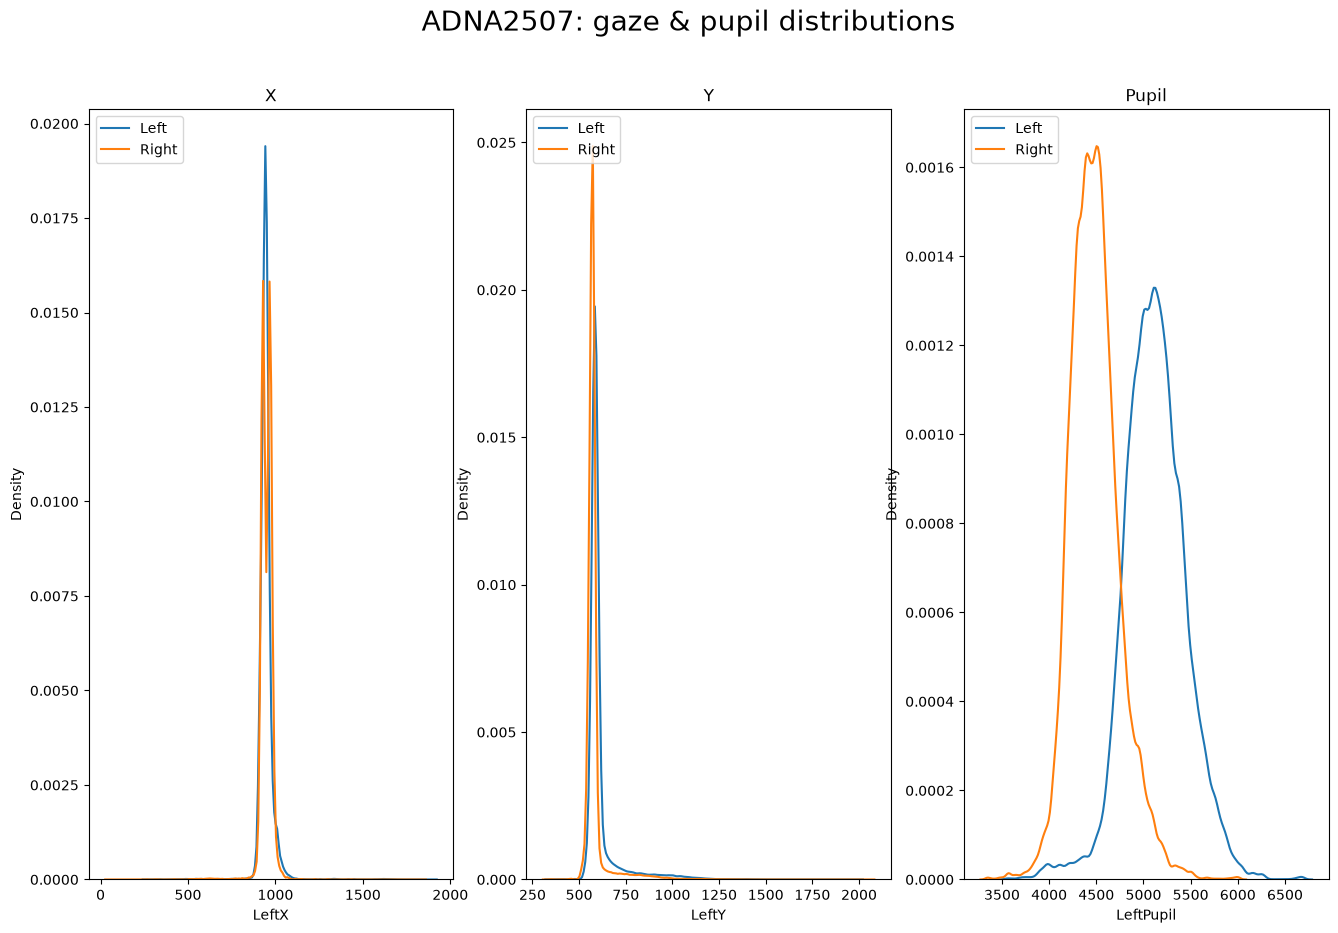

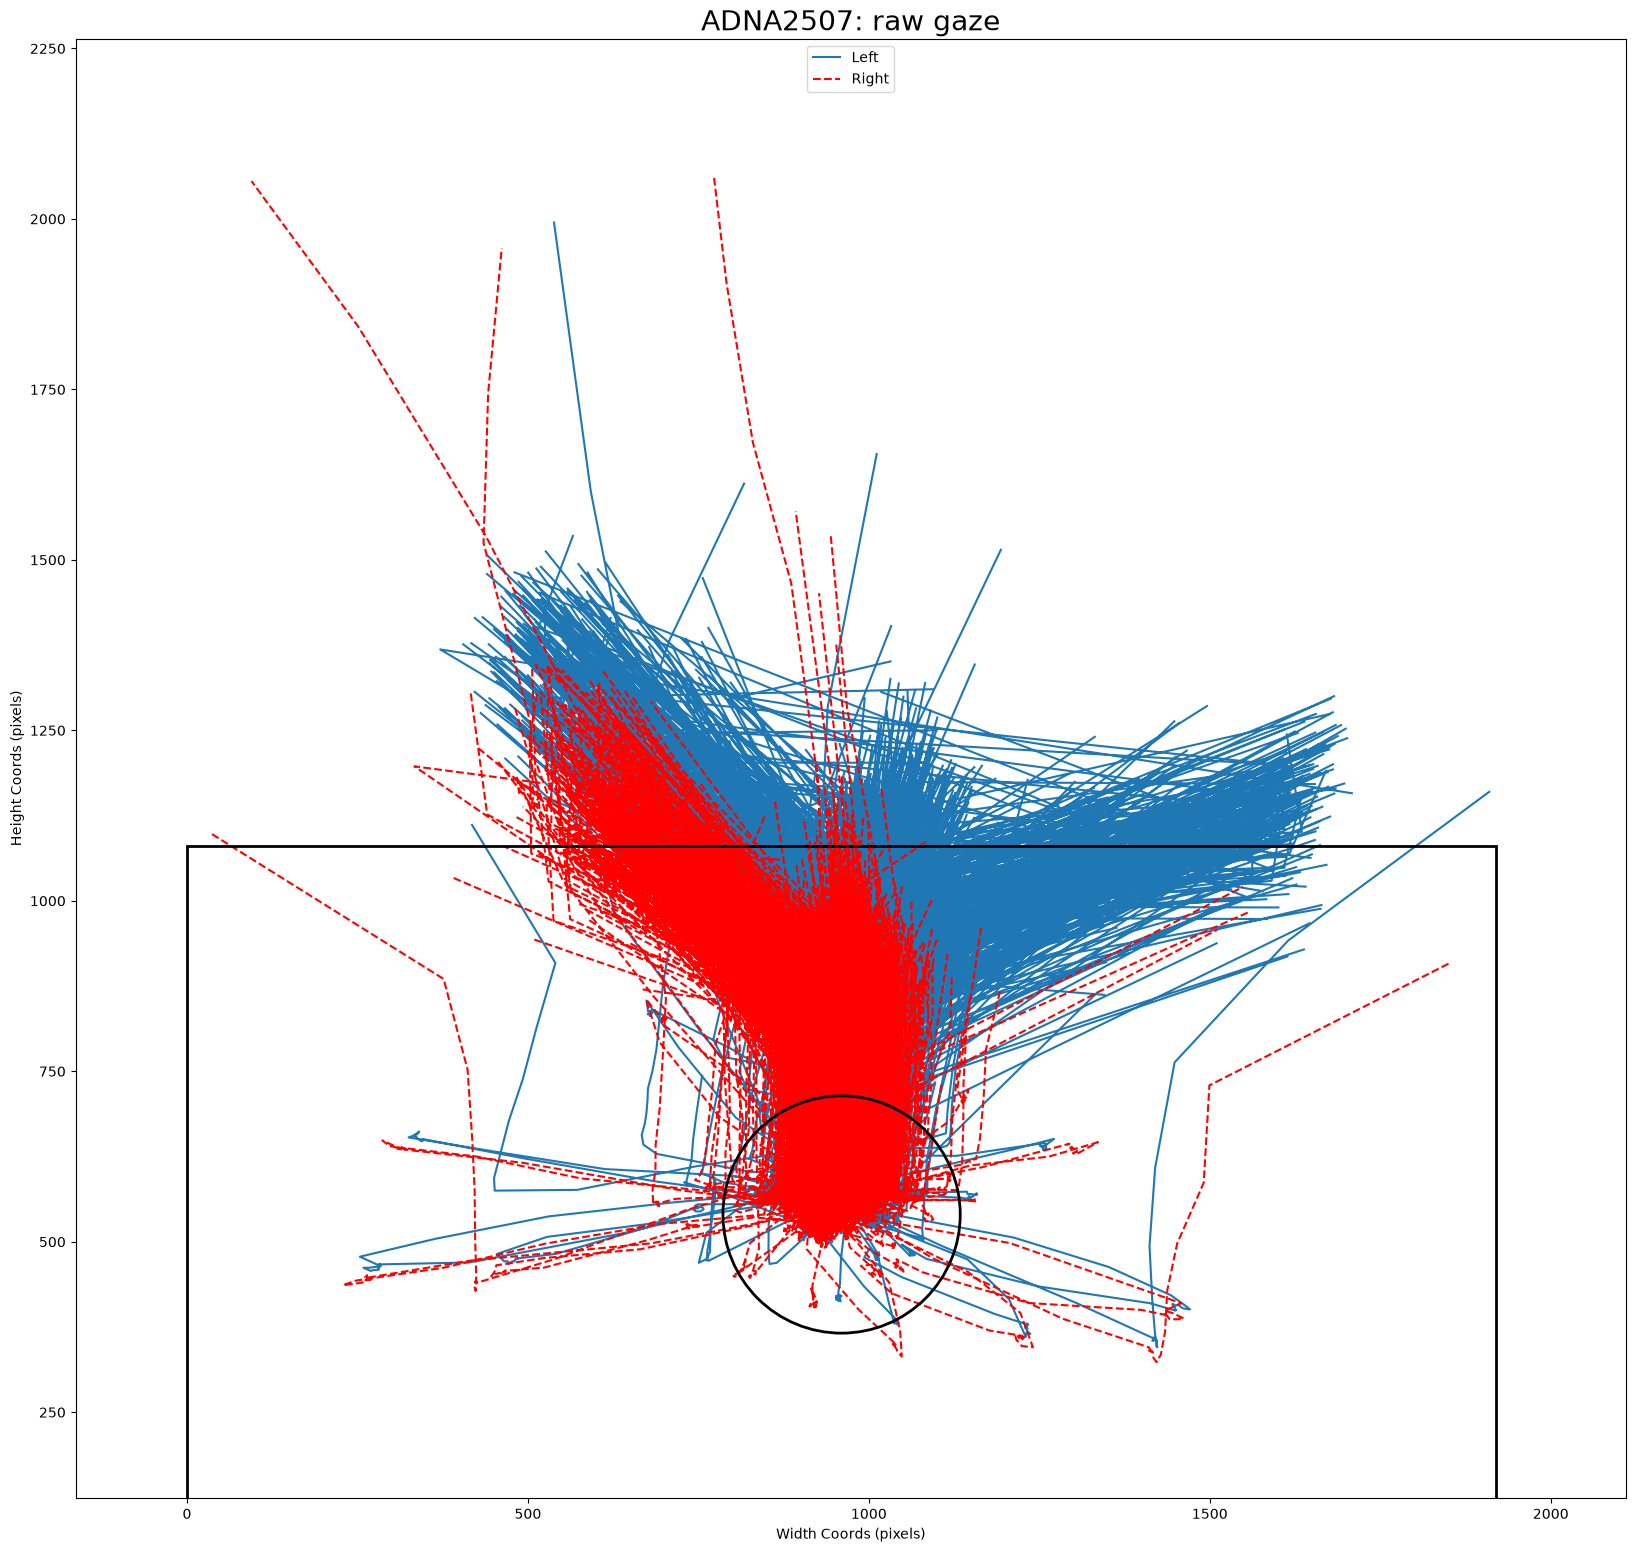

In [11]:
fig1 = eyeRawKDE(gaze[gaze.Subject == subj], titl=f'{subj}: gaze & pupil distributions')
fig2 = plotRawGaze(gaze[gaze.Subject == subj], SCREEN, titl=f'{subj}: raw gaze')

### Visualize: pupil timecourse (one trial)

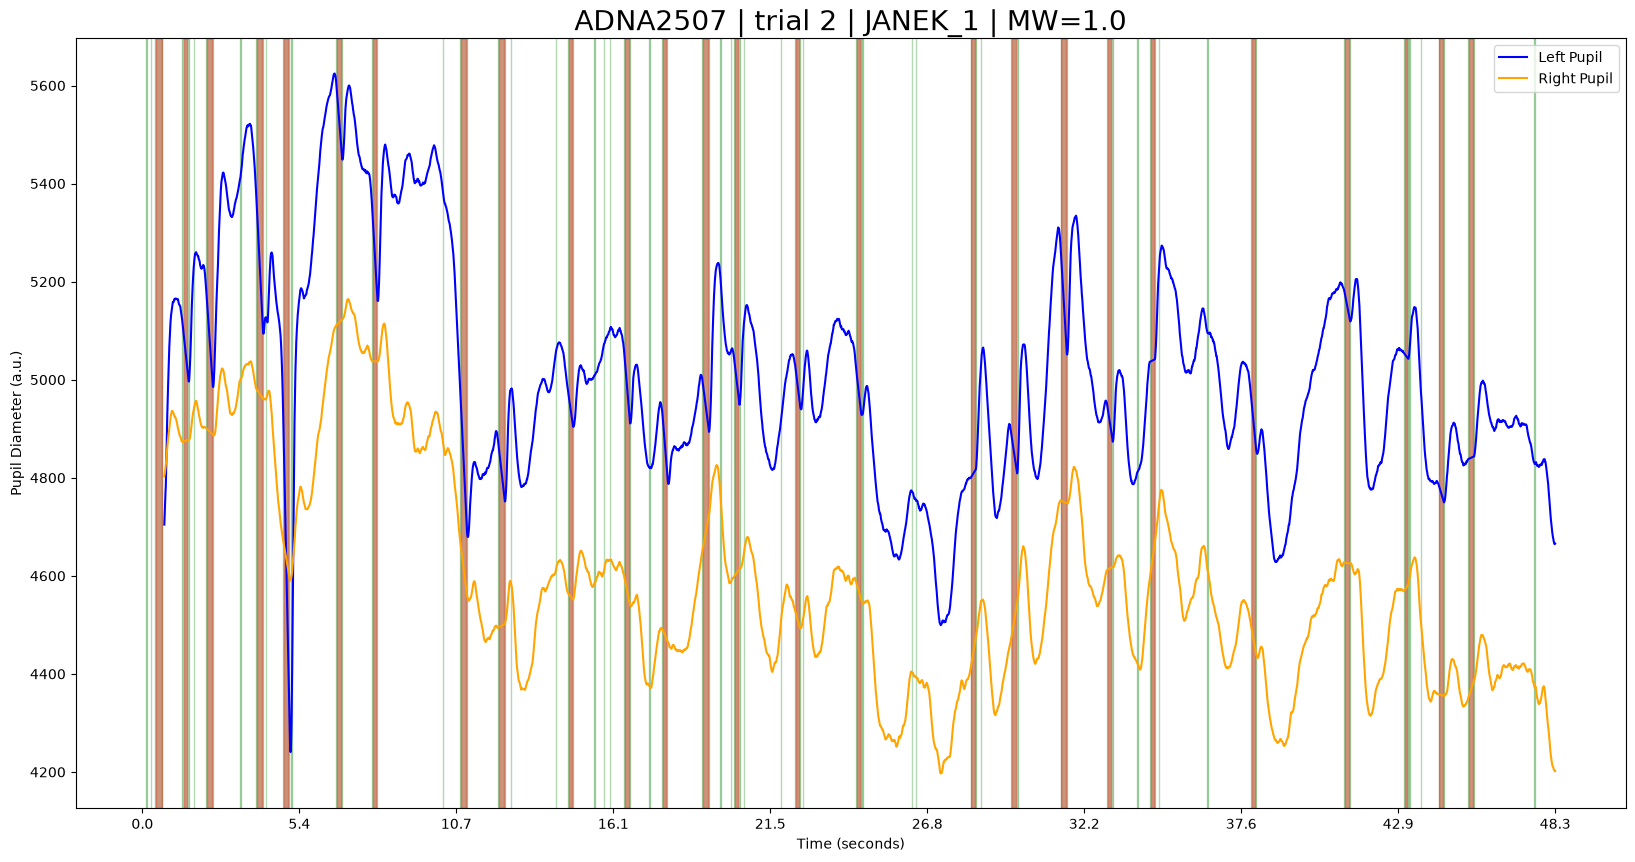

In [12]:
fig3 = plotPupilTimecourse(g, title, b, s, f, chooseViz='011', secChan=1)

### Interactive (separate window; afterwards run `%matplotlib inline` to go back)

In [13]:
# %matplotlib qt
# interactive_pupil_plot(ScreenData=g, blinks=b, saccades=s, fixations=f,
#                        gazeCoords=SCREEN, window_size=2000, chooseViz='011')

## Recalls: przeglądanie wypowiedzi badanych
Fragment historii | wypowiedź | lematy | MW. Lista wyboru badanego + przyciski.

In [14]:
%matplotlib inline
from storyTools import history_viewer

recalls = pd.read_csv(D + '/behavioral.csv')          # ma Utterance, Lemmas, StoryFrag
errors  = history_viewer(recalls)                     # errors -> {Subject: {Fragment: True/False}}

### Metryki wypowiedzi: długość, lexical diversity, autobiograficzność, semantic coupling
Wymaga stosu NLP: `pip install -r requirements-nlp.txt`

In [15]:
# Modele ładujesz RAZ (sBERT ~0.5 GB, pobierze się przy pierwszym uruchomieniu)
import morfeusz2
from sentence_transformers import SentenceTransformer
from storyTools import utterance_report

morf  = morfeusz2.Morfeusz()
sbert = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
w2v   = None   # opcjonalnie fastText: from gensim.models import fasttext as ftx; w2v = ftx.load_facebook_model(r'...\w2v_pl.bin')


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [16]:
# Raport dla wybranego badanego/triala (subj, trial z sekcji wyżej)
row = recalls[(recalls.Subject == subj) & (recalls.TrialNum == trial)].iloc[0]
m = utterance_report(row, morf=morf, sbert=sbert, w2v=w2v)


──────────────────────────────────────────────────────────────────────────────
 ADNA2507 | 2 | JANEK_1
 MW=1.00 | MW_Estimate=-0.77 | Tracking=TRACKED
──────────────────────────────────────────────────────────────────────────────
 WYPOWIEDŹ:  Janek jest cieślą tak jak jego ojciec. Chce wykonywać jakieś ambitne rzeczy. Jest też hojny i rozdawał pieniądze ubogim.
──────────────────────────────────────────────────────────────────────────────
 DŁUGOŚĆ
   słowa / zdania / lematy           : 19 / 3 / 12
 RÓŻNORODNOŚĆ LEKSYKALNA
   lexical diversity (TTR)           :  1.000   unikalne lematy / wszystkie lematy (1 = brak powtórzeń)
   lexical diversity vs historia     :  0.197   unikalne lematy wypowiedzi / unikalne lematy fragmentu
   wspólne lematy z historią         :  0.417   odsetek lematów wypowiedzi, które są też w fragmencie
 AUTOBIOGRAFICZNOŚĆ
   odniesienia do siebie (razem)     :      0   = czasowniki 1 os. l.poj. + zaimki 1 os.
     czasowniki 1 os. l.poj.  ( 0)  : -
     zaimki ja